# Bank deposits: marginal cost from public aggregates

A bank comparing deposits with another source of funding needs the cost
of the *next* dollar raised. The posted deposit rate measures the
interest paid on the existing balance. Raising that rate also reprices
deposits that would have stayed at the bank, so the next dollar can cost
much more than the posted rate.

The missing input is the **own-rate response**: the increase in a bank's
deposits when that bank raises its rate and market conditions remain
fixed. Public aggregate series do not observe that experiment. They
record total balances, market rates, and national average deposit rates,
all moving with monetary policy and the economy.

The empirical test is whether those aggregates nevertheless produce a
stable enough rate response to support the marginal-cost calculation.
Two samples expose the trade-off. Historical M1 data cover
double-digit rates but do not measure bank deposits or the rates paid on
them. Modern data measure commercial-bank deposits and an offered
deposit rate, but most of their rate variation comes from one monetary
tightening cycle.

The estimated rate-response curve changes shape when plausible trend or
balance-sheet controls change. Substituting either sample's fitted slopes into
the marginal-cost formula therefore gives large costs that depend on the
specification. The aggregates are
useful for showing how the repricing arithmetic works and how fragile
its empirical input can be. They are not a basis for pricing a deposit
campaign or comparing it with wholesale funding.

This case teaches a time-series workflow for derivatives of a fitted smooth: define the
economic quantity, tune with rolling origins, translate the slope into units of the
decision, and test its sensitivity to the controls.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the cost of the next dollar of deposits, which the posted rate does not measure |
| **Observed response** | deposit quantity, modelled against rate and macro conditions |
| **Estimand** | the marginal cost of funds — an elasticity, not the average rate paid |
| **Units** | rates in percentage points, balances in dollars; the elasticity is unitless |
| **Sampling unit** | one month of the aggregate US deposit market; 208 months |
| **Dependence** | a time series — months are serially dependent, and the study is explicit that this limits what the aggregate can identify |
| **Split / resampling unit** | rolling origins for forecast validation; blocks of adjacent quarters or months for residual resampling |
| **Tuning** | fixed `mstop` |
| **Uncertainty** | bootstrap, with the serial dependence noted as a caveat on it |
| **Claim type** | descriptive of the aggregate series. The study's own conclusion is that public aggregates cannot identify the marginal cost |
:::


## Marginal deposit cost

Let $D(r_d)$ be a bank's deposit balance when its annual offered rate
$r_d$ is measured in percentage points. The own-rate sensitivity is
$\eta(r_d)=\partial\log D(r_d)/\partial r_d$: the local percentage
change in deposits associated with a one-percentage-point increase in
the bank's rate.

If the new rate applies to the whole balance, annual interest expense is
$I(r_d)=r_dD(r_d)/100$. Differentiating expense with respect to deposits
gives marginal funding cost in percentage points,
$MC(r_d)=100\,\partial I/\partial D=r_d+1/\eta(r_d)$.

The reciprocal $1/\eta$ is the repricing term. A weak deposit response
makes it large because the bank pays more on many existing dollars to
attract few new ones. The formula changes when only new balances receive
a promotional rate, and it excludes fees, servicing costs, and changes
in deposit composition.

This identity fixes the empirical requirement. A funding decision needs
the response to a change in the bank's own rate, with competing rates
and other determinants of deposits held fixed. The models below instead
estimate an aggregate rate sensitivity
$\theta(s)=-\partial\log Q/\partial s$, where $Q$ is an aggregate
balance measure and $s$ is an opportunity-cost proxy. Reporting
$1/\theta$ shows the cost implied *if* that aggregate slope equaled the
own-rate response; it does not make the two quantities equal.


## Historical and modern samples

| Requirement | Historical sample | Modern sample |
|---|---|---|
| Balance measure | M1 relative to GDP | Commercial-bank deposits relative to personal income |
| Rate measure | Three-month Treasury bill rate | Federal funds rate minus the national offered money-market deposit rate |
| Useful feature | Covers a full cycle including double-digit market rates | Uses a deposit balance and an observed offered-rate proxy |
| Binding limit | M1 includes currency and several account types; the paid deposit rate is absent | National aggregates provide no bank-level own-rate variation; the wide spreads occur in one tightening episode |

The historical sample asks whether the aggregate slope changes across a
wide range of market rates. The modern sample asks whether a closer
deposit measure produces a stable slope across the offered-rate spread.
Agreement would not establish causality, but disagreement or
specification sensitivity is enough to reject these series as a pricing
input.


## Historical sample: M1 and the Treasury bill rate

`mb.datasets.usmacro()` contains quarterly US macroeconomic aggregates.
The analysis ends in 1993Q4 because retail sweep programs began moving
transaction-account balances into savings accounts during 1994 and
reduced measured M1 without an equivalent change in customer liquidity
{cite:p}`anderson2001sweeps`.

Before 1994 M1 included currency, demand deposits, and other checkable
deposits. The last category included interest-bearing NOW and ATS
accounts; M1 was therefore neither a deposit total nor a zero-rate
product ([Federal Reserve H.6](https://www.federalreserve.gov/Releases/H6/20210323/)).
The response is the logarithm of real M1 divided by real GDP. This ratio
expresses transaction money relative to output, but it does not isolate
bank funding or remove every common trend.

The three-month Treasury bill rate proxies for the return forgone by
holding transaction money. Because the rates paid on the deposit
components of M1 are unavailable, the bill rate is not an observed
opportunity-cost spread. The historical model therefore estimates a
money-demand association with the bill rate.


In [1]:
import warnings
# Compute the table or diagnostic interpreted in the following paragraph.
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

macro = mb.datasets.usmacro().filter(pl.col("year") <= 1993)
n_hist = macro.height
rate = macro["tbilrate"].to_numpy()
real_m1 = macro["m1"].to_numpy() / (macro["cpi"].to_numpy() / 100.0)
log_ratio = np.log(real_m1 / macro["realgdp"].to_numpy())

historical = pl.DataFrame({
    "y": log_ratio,
    "r": rate,
    "r_c": rate - rate.mean(),
    "t_c": np.arange(1, n_hist + 1, dtype=float) - (n_hist + 1) / 2.0,
    "infl_c": macro["infl"].to_numpy() - macro["infl"].mean(),
    "date": macro["year"].to_numpy() + (macro["quarter"].to_numpy() - 1) / 4,
})

rate_lo, rate_hi = f"{rate.min():.2f}", f"{rate.max():.2f}"
rate_ratio_corr = f"{np.corrcoef(rate, log_ratio)[0, 1]:.2f}"

print(f"{n_hist} quarters, 1959Q1 to 1993Q4")
print(f"T-bill rate: {rate_lo}% to {rate_hi}%, mean {rate.mean():.2f}%")
print(f"log(real M1 / real GDP): {log_ratio.min():.3f} to {log_ratio.max():.3f}")


140 quarters, 1959Q1 to 1993Q4
T-bill rate: 2.29% to 15.33%, mean 6.11%
log(real M1 / real GDP): -2.576 to -1.727


The sample contains {eval}`n_hist` quarters, and the bill rate ranges
from {eval}`rate_lo`% to {eval}`rate_hi`%. That coverage is the reason to
use the old data: the upper end supplies observations for estimating a
slope at rates absent from the modern sample. The money-output ratio and
bill rate have a sample correlation of {eval}`rate_ratio_corr`, which
establishes the inverse aggregate movement but not its cause.


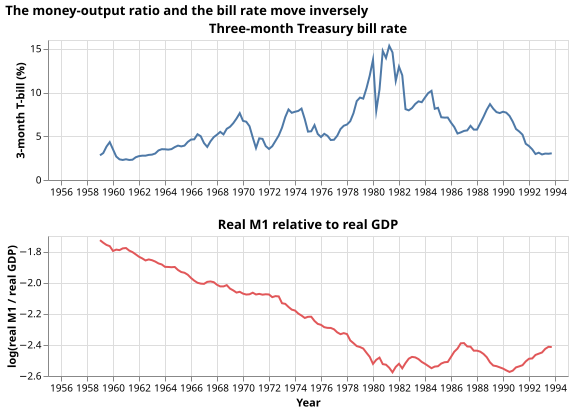

In [2]:
history = pl.DataFrame({
    "date": historical["date"], "rate": rate, "log_ratio": log_ratio,
})
rate_line = alt.Chart(history).mark_line(color="#4e79a7").encode(
    x=alt.X("date:Q", title=None, axis=alt.Axis(format="d")),
    y=alt.Y("rate:Q", title="3-month T-bill (%)"),
).properties(width=520, height=140, title="Three-month Treasury bill rate")
ratio_line = alt.Chart(history).mark_line(color="#e15759").encode(
    x=alt.X("date:Q", title="Year", axis=alt.Axis(format="d")),
    y=alt.Y("log_ratio:Q", title="log(real M1 / real GDP)",
            scale=alt.Scale(zero=False)),
).properties(width=520, height=140,
             title="Real M1 relative to real GDP")
alt.vconcat(rate_line, ratio_line).resolve_scale(x="shared").properties(
    title="The money-output ratio and the bill rate move inversely")

The money-output ratio falls during the long rise in rates and recovers
as rates decline. Calendar time has a similar low-frequency pattern, so
the estimated rate curve depends on how the model divides that movement
between the rate and the trend. This is the main specification risk in
the historical analysis.


## Historical model with time-ordered validation

The model gives the bill rate separate linear and nonlinear candidates.
A linear time trend competes with them, while inflation also enters as
linear and nonlinear candidates. Component-wise gradient boosting fits
every candidate to the current unexplained part, updates the
best-fitting one by a small amount, and repeats
{cite:p}`hofner2011framework`.

Every candidate has one degree of freedom. For the rate and inflation,
`bols(..., intercept=False)` represents the straight-line component.
`bbs(..., center=True, df=1)` removes the spline's constant and linear
components, leaving curvature as a separate candidate. Matching their
flexibility prevents the curved candidate from being selected merely
because it can fit more shapes at each step.

The number of boosting steps controls total complexity. Random folds
would train on later quarters and score earlier ones, so they do not
reproduce a forecast from the past into the future. Rolling-origin
validation fits through a cutoff, predicts the following four quarters,
advances the cutoff by a year, and pools error across ten origins. The
selected model is tuned for one-year-ahead prediction; this controls
overfitting but does not turn its slope into a causal effect.


In [3]:
FORMULA = (
    "y ~ bols(r_c, intercept=False) + bbs(r_c, center=True, df=1)"
    " + bols(t_c, intercept=False) + bols(infl_c, intercept=False)"
    " + bbs(infl_c, center=True, df=1)"
)

LEARNERS = ["bols(r)", "bbs(r)", "bols(t)", "bols(infl)", "bbs(infl)"]

NU = 0.05

def fit_historical(frame, mstop, formula=FORMULA):
    return mb.gamboost(formula, data=frame, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=mstop, nu=NU))


In [4]:
def theta_historical(model, points, step=0.05):
    """-d log Q / d r at `points`, with trend and inflation held at their means.

    Every covariate enters centered, so setting the others to zero evaluates
    the fit at the sample mean of each. `predict(which=)` would be the direct
    route to a single learner's contribution, but it silently drops learners
    that were never selected, which shifts the column indices; predicting over
    a grid where only the rate moves avoids the bookkeeping.
    """
    points = np.asarray(points, dtype=float)

    def at(values):
        grid = pl.DataFrame({
            "y": np.zeros(len(values)), "r": values,
            "r_c": values - rate.mean(), "t_c": np.zeros(len(values)),
            "infl_c": np.zeros(len(values)), "date": np.zeros(len(values)),
        })
        with warnings.catch_warnings():
            # The endpoints of the grid step half a tenth of a point outside
            # the observed rates, where the spline extrapolates linearly.
            warnings.simplefilter("ignore")
            return np.asarray(model.predict(newdata=grid)).ravel()

    return -(at(points + step) - at(points - step)) / (2 * step)


In [5]:
def rolling_cv(frame, grid, formula=FORMULA, folds=10, horizon=4,
               fitter=None, response="y"):
    """Root mean squared error of `horizon`-step-ahead forecasts, pooled over folds."""
    fitter = fitter or (lambda f, m: fit_historical(f, m, formula))
    n = frame.height
    squared = np.zeros(len(grid))
    scored = 0
    for k in range(folds):
        cut = n - (folds - k) * horizon
        model = fitter(frame[:cut], int(max(grid)))
        test = frame[cut:cut + horizon]
        actual = test[response].to_numpy()
        for j, m in enumerate(grid):
            predicted = np.asarray(model.predict(newdata=test, mstop=int(m))).ravel()
            squared[j] += np.sum((actual - predicted) ** 2)
        scored += test.height
    return np.sqrt(squared / scored)


with warnings.catch_warnings():
    # Held-out quarters can lie outside the training range of the rate, where
    # the spline extrapolates linearly. That is the honest forecast situation.
    warnings.simplefilter("ignore")
    grid = np.arange(1, 3001)
    cv_curve = rolling_cv(historical, grid)

mstop_star = int(grid[int(np.argmin(cv_curve))])
rmse_star = f"{cv_curve.min():.4f}"
rmse_50, rmse_3000 = f"{cv_curve[49]:.4f}", f"{cv_curve[-1]:.4f}"
print(f"CV-selected mstop: {mstop_star}  (RMSE {rmse_star})")
print(f"RMSE at mstop 50 / 500 / 3000: {rmse_50} / "
      f"{cv_curve[499]:.4f} / {rmse_3000}")

CV-selected mstop: 172  (RMSE 0.0866)
RMSE at mstop 50 / 500 / 3000: 0.1113 / 0.0908 / 0.1142


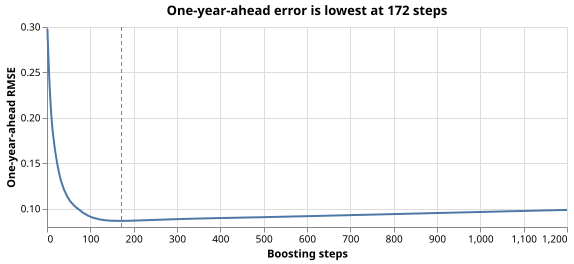

In [6]:
alt.Chart(pl.DataFrame({"mstop": grid[:1200], "rmse": cv_curve[:1200]})).mark_line(
    color="#4e79a7"
).encode(
    x=alt.X("mstop:Q", title="Boosting steps"),
    y=alt.Y("rmse:Q", title="One-year-ahead RMSE", scale=alt.Scale(zero=False)),
).properties(
    width=520, height=200,
    title=f"One-year-ahead error is lowest at {mstop_star} steps"
) + alt.Chart(
    pl.DataFrame({"mstop": [mstop_star]})
).mark_rule(color="#e15759", strokeDash=[4, 3]).encode(x="mstop:Q")

One-year-ahead root mean squared error reaches its minimum at
{eval}`mstop_star` boosting steps, where it is {eval}`rmse_star` log
points of the money-output ratio. The error is {eval}`rmse_50` at step
`50` and {eval}`rmse_3000` at step `3000`. The increase after the
minimum shows that later updates worsen forecasts, so the slope is read
from the selected path rather than its most complex endpoint.


## Historical rate sensitivity and implied cost

Rate sensitivity is the negative slope of the fitted rate component,
measured in log points of the money-output ratio per percentage-point
increase in the bill rate. A centered finite difference evaluates the
slope while time and inflation are held at their sample means.

The reciprocal column applies the marginal-cost identity under the
additional assumption that the aggregate bill-rate slope equals a
bank's own-rate deposit response. It reports the repricing term only;
the historical average deposit rate needed to add the posted-rate term
is not observed.


In [7]:
model_hist = fit_historical(historical, mstop_star)
points = np.array([3.0, 5.0, 8.0, 11.0, 14.0])
theta_hist = theta_historical(model_hist, points)

display(pl.DataFrame({
    "r (%)": points,
    "sensitivity": np.round(theta_hist, 4),
    "conditional repricing term, 1/theta (pp)": np.round(1 / theta_hist, 1),
}))

selection = np.bincount(model_hist.path_frame()["learner_index"].to_numpy(),
                        minlength=len(LEARNERS))
theta_3, theta_14 = f"{theta_hist[0]:.4f}", f"{theta_hist[-1]:.4f}"
theta_ratio = f"{theta_hist[-1] / theta_hist[0]:.0%}"
mc_3, mc_14 = f"{1 / theta_hist[0]:.0f}", f"{1 / theta_hist[-1]:.0f}"
sel_line, sel_bend = int(selection[0]), int(selection[1])
sel_trend, sel_infl_bend = int(selection[2]), int(selection[4])
infl_line_phrase = ("never won a step" if selection[3] == 0
                    else f"won {selection[3]} of them")
print(f"\nin-sample residual sd: "
      f"{np.std(historical['y'].to_numpy() - model_hist.fitted()):.4f}")
print("steps won per candidate:", dict(zip(LEARNERS, selection.tolist())))

r (%),sensitivity,"conditional repricing term, 1/theta (pp)"
f64,f64,f64
3.0,0.0351,28.5
5.0,0.0339,29.5
8.0,0.0305,32.8
11.0,0.0234,42.8
14.0,0.0187,53.4



in-sample residual sd: 0.0425
steps won per candidate: {'bols(r)': 38, 'bbs(r)': 70, 'bols(t)': 58, 'bols(infl)': 0, 'bbs(infl)': 6}


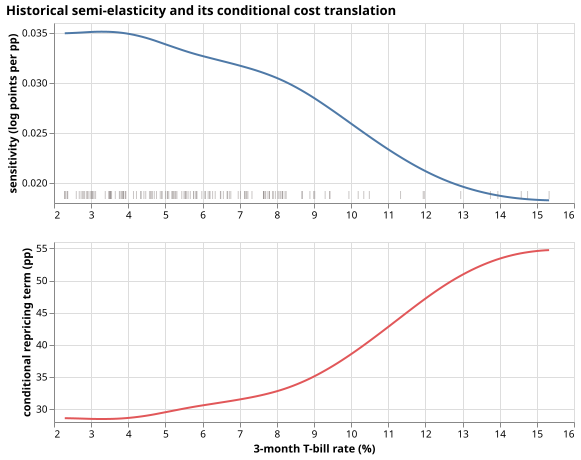

In [8]:
curve_r = np.linspace(rate.min(), rate.max(), 120)
curve = pl.DataFrame({"r": curve_r, "theta": theta_historical(model_hist, curve_r)})
curve = curve.with_columns(mc=1 / pl.col("theta"))
observed_rug = pl.DataFrame({"r": rate})

sensitivity_panel = alt.Chart(curve).mark_line(
    color="#4e79a7", strokeWidth=2
).encode(
    x=alt.X("r:Q", title=None),
    y=alt.Y("theta:Q", title="sensitivity (log points per pp)",
            scale=alt.Scale(zero=False)),
).properties(width=520, height=180) + alt.Chart(observed_rug).mark_tick(
    color="#79706e", opacity=0.4, size=8, yOffset=82
).encode(x="r:Q")

cost_panel = alt.Chart(curve).mark_line(color="#e15759", strokeWidth=2).encode(
    x=alt.X("r:Q", title="3-month T-bill rate (%)"),
    y=alt.Y("mc:Q", title="conditional repricing term (pp)",
            scale=alt.Scale(zero=False)),
).properties(width=520, height=180)

alt.vconcat(sensitivity_panel, cost_panel).resolve_scale(x="shared").properties(
    title="Historical semi-elasticity and its conditional cost translation")

The fitted sensitivity falls from {eval}`theta_3` at a bill rate of
three percent to {eval}`theta_14` at fourteen percent. Conditional on
the own-rate interpretation, the corresponding repricing terms rise
from {eval}`mc_3` to {eval}`mc_14` percentage points.

Those magnitudes show why the response estimate matters: substituting
the fitted slopes into a funding comparison would make deposits appear
progressively more expensive at high rates. The measurement does not
support that decision. M1 is not the bank's deposit balance, the bill
rate is not its offered rate, and aggregate monetary conditions are not
held fixed. The defensible empirical claim at this stage is only that
the selected aggregate curve becomes flatter as the bill rate rises.


## Sensitivity to the time trend

A moving-block residual bootstrap first checks sampling variation
within the selected model. Blocks of eight adjacent quarters preserve
short runs of serial dependence. The rate path, controls, and selected
number of steps remain fixed, so the resulting range is conditional on
those choices.


In [9]:
fitted_hist = model_hist.fitted()
residual_hist = historical["y"].to_numpy() - fitted_hist
# Fix the random draw so the resampling result is reproducible.

def moving_blocks(rng, residuals, length):
    """Resample a residual series in blocks of `length`, wrapping at the end."""
    n = len(residuals)
    starts = rng.integers(0, n, size=int(np.ceil(n / length)))
    drawn = [np.take(residuals, np.arange(s, s + length), mode="wrap") for s in starts]
    return np.concatenate(drawn)[:n]


def curvature_of(model):
    ends = theta_historical(model, np.array([3.0, 14.0]))
    return ends[0] - ends[1]


curvature_hat = curvature_of(model_hist)
rng = np.random.default_rng(20260817)
fixed_mstop = np.empty(300)
for b in range(300):
    resampled = historical.with_columns(
        pl.Series("y", fitted_hist + moving_blocks(rng, residual_hist, 8)))
    fixed_mstop[b] = curvature_of(fit_historical(resampled, mstop_star))

lo, hi = np.quantile(fixed_mstop, [0.10, 0.90])
n_boot = len(fixed_mstop)
curvature_fmt = f"{curvature_hat:.4f}"
fixed_lo, fixed_hi = f"{lo:.4f}", f"{hi:.4f}"
fixed_p = f"{(fixed_mstop > 0).mean():.0%}"
print(f"theta(3) - theta(14) = {curvature_fmt}")
print(f"block bootstrap, mstop fixed at {mstop_star}: "
      f"80% interval [{fixed_lo}, {fixed_hi}], width {hi - lo:.4f}, "
      f"share above zero {fixed_p}")


theta(3) - theta(14) = 0.0164
block bootstrap, mstop fixed at 172: 80% interval [0.0006, 0.0248], width 0.0242, share above zero 92%


The fitted decline $\theta(3)-\theta(14)$ is
{eval}`curvature_fmt`. The central eighty percent of the bootstrap
estimates runs from {eval}`fixed_lo` to {eval}`fixed_hi`, and
{eval}`fixed_p` of the estimates are positive. Residual variation alone
therefore rarely removes the decline from the selected specification.

Specification uncertainty asks a different question. The original
model restricts calendar time to a straight line. The comparison below
gives time the same straight-plus-curved decomposition as the rate; a
second comparison removes inflation. Each model selects its own number
of steps on the same rolling origins.


In [10]:
# The fall is a property of the rate term, which competes with a linear time
# trend over a period in which rates rose for twenty years and then fell. These
# alternatives are stopped by the same rolling-origin cross-validation.
SMOOTH_TREND = (
    "y ~ bols(r_c, intercept=False) + bbs(r_c, center=True, df=1)"
    " + bols(t_c, intercept=False) + bbs(t_c, center=True, df=1)"
    " + bols(infl_c, intercept=False) + bbs(infl_c, center=True, df=1)"
)

NO_INFLATION = (
    "y ~ bols(r_c, intercept=False) + bbs(r_c, center=True, df=1)"
    " + bols(t_c, intercept=False)"
)

rows, alt_fall = [], {}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for label, formula in (("as fitted above", FORMULA),
                           ("time trend also free to bend", SMOOTH_TREND),
                           ("inflation dropped", NO_INFLATION)):
        curve = rolling_cv(historical, np.arange(1, 1201), formula=formula)
        best = int(np.arange(1, 1201)[int(np.argmin(curve))])
        ends = theta_historical(fit_historical(historical, best, formula),
                                np.array([3.0, 14.0]))
        alt_fall[label] = (float(ends[0] - ends[1]), float(curve.min()), ends)
        rows.append({"fitted on": label, "rate range": "3 to 14",
                     "mstop": best, "CV RMSE": round(float(curve.min()), 4),
                     "at the low end": round(float(ends[0]), 4),
                     "at the high end": round(float(ends[1]), 4),
                     "fall": round(float(ends[0] - ends[1]), 4)})


In [11]:
display(pl.DataFrame(rows))

fall_smooth_trend = f"{alt_fall['time trend also free to bend'][0]:.4f}"

rmse_smooth_trend = f"{alt_fall['time trend also free to bend'][1]:.4f}"

flat_theta = f"{alt_fall['time trend also free to bend'][2][0]:.4f}"

fall_no_infl = f"{alt_fall['inflation dropped'][0]:.4f}"

rmse_no_infl = f"{alt_fall['inflation dropped'][1]:.4f}"


fitted on,rate range,mstop,CV RMSE,at the low end,at the high end,fall
str,str,i64,f64,f64,f64,f64
"""as fitted above""","""3 to 14""",172,0.0866,0.0351,0.0187,0.0164
"""time trend also free to bend""","""3 to 14""",113,0.0925,0.0239,0.0239,0.0
"""inflation dropped""","""3 to 14""",1199,0.0756,0.0405,0.0064,0.0341


Allowing the time trend to curve reduces the fitted decline to
{eval}`fall_smooth_trend`; the sensitivity is approximately
{eval}`flat_theta` across the rate range. Its forecast error is
{eval}`rmse_smooth_trend`, against {eval}`rmse_star` for the linear
trend. Removing inflation moves the estimate in the other direction:
the decline becomes {eval}`fall_no_infl`, and forecast error falls to
{eval}`rmse_no_infl`.

The historical data support an inverse association between M1 relative
to GDP and the bill rate. They do not support a stable conclusion about
how that association changes with the rate level. The decline survives
residual resampling but disappears under a plausible trend model; the
stronger decline after removing inflation shows that low-frequency
terms can reallocate the shape in either direction. Consequently, the
conditional repricing terms are scenario calculations, not estimates
for a funding decision.


## Modern sample: deposits and the deposit-rate spread

`mb.datasets.deposit_market()` combines monthly commercial-bank
deposits, personal income, the effective federal funds rate, the
Federal Reserve's balance sheet, and the FDIC national money-market
deposit rate. The response is log aggregate deposits divided by
personal income. The spread is the federal funds rate minus the offered
deposit rate, so a larger value means that the national deposit rate
lags the policy rate.

The FDIC series is an average of rates offered on new accounts, not the
balance-weighted rate paid on existing deposits. Its method changes in
April 2021: the earlier average is weighted by branches and excludes
credit unions, while the later average is weighted by domestic deposit
share and includes them ([FDIC methodology](https://www.fdic.gov/national-rates-and-rate-caps/national-rates-and-rate-caps-21)).

This sample moves closer to the funding question because both the
balance and rate proxy concern deposits. It remains one national time
series. Changes in the spread coincide with monetary policy, Federal
Reserve asset holdings, income, and bank funding needs, so the fitted
slope cannot isolate the response to one bank changing its rate.


In [12]:
market = mb.datasets.deposit_market().drop_nulls(
    subset=["fedfunds", "deposits", "personal_income", "natl_mmda", "cpi"])
n_mod = market.height
spread = (market["fedfunds"] - market["natl_mmda"]).to_numpy()
balance_sheet = np.log(market["walcl"].to_numpy()
                       / (market["personal_income"].to_numpy() * 1000))
dates = market["date"].to_numpy()

modern = pl.DataFrame({
    "y": np.log(market["deposits"].to_numpy() / market["personal_income"].to_numpy()),
    "s": spread,
    "s_c": spread - spread.mean(),
    "bs_c": balance_sheet - balance_sheet.mean(),
    "t_c": np.arange(1, n_mod + 1, dtype=float) - (n_mod + 1) / 2.0,
    "covid": ((dates >= "2020-03-01") & (dates <= "2020-07-01")).astype(float),
    "svb": ((dates >= "2023-03-01") & (dates <= "2023-05-01")).astype(float),
})

print(f"{n_mod} months, {dates[0]} to {dates[-1]}")
print(f"spread: {spread.min():.2f} to {spread.max():.2f} percentage points")
seam = market.filter(pl.col("date").is_between(pl.lit("2021-01-01"), pl.lit("2021-06-01")))
print("\nmonths either side of the change in the FDIC calculation:")
display(seam.select("date", "fedfunds", "natl_mmda", "mmda_source"))

# The last month of the FRED segment and the first of the FDIC segment.
last_fred = seam.filter(pl.col("mmda_source") == "fred_mmnrnj")["natl_mmda"][-1]
first_fdic = seam.filter(pl.col("mmda_source") == "fdic_page")["natl_mmda"][0]
assert last_fred == first_fdic, "the two segments no longer meet at one rate"
seam_rate = f"{last_fred:.2f}"

205 months, 2009-05-01 to 2026-06-01
spread: -0.29 to 4.71 percentage points

months either side of the change in the FDIC calculation:


date,fedfunds,natl_mmda,mmda_source
str,f64,f64,str
"""2021-01-01""",0.09,0.07,"""fred_mmnrnj"""
"""2021-02-01""",0.08,0.06,"""fred_mmnrnj"""
"""2021-03-01""",0.07,0.06,"""fred_mmnrnj"""
"""2021-04-01""",0.07,0.06,"""fdic_page"""
"""2021-05-01""",0.06,0.1,"""fdic_page"""
"""2021-06-01""",0.08,0.09,"""fdic_page"""


The two FDIC methods both report {eval}`seam_rate`% in the months on
either side of the change. The absence of a visible jump at that point
avoids a mechanical break in the fitted level, but it does not make the
two weighting schemes equivalent.


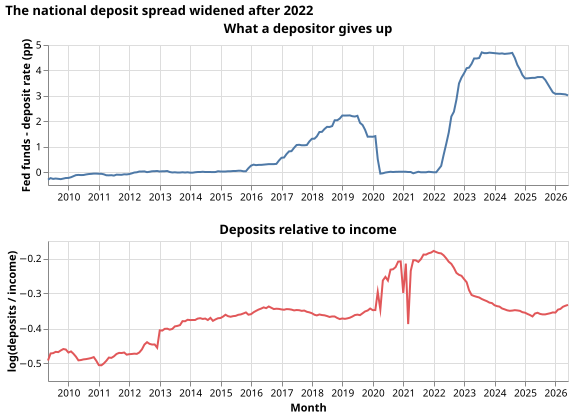

In [13]:
panel = pl.DataFrame({
    "date": [str(d) for d in dates], "spread": spread,
    "log_ratio": modern["y"].to_numpy(),
})
spread_line = alt.Chart(panel).mark_line(color="#4e79a7").encode(
    x=alt.X("date:T", title=None),
    y=alt.Y("spread:Q", title="Fed funds - deposit rate (pp)"),
).properties(width=520, height=140, title="What a depositor gives up")
balance_line = alt.Chart(panel).mark_line(color="#e15759").encode(
    x=alt.X("date:T", title="Month"),
    y=alt.Y("log_ratio:Q", title="log(deposits / income)",
            scale=alt.Scale(zero=False)),
).properties(width=520, height=140, title="Deposits relative to income")
alt.vconcat(spread_line, balance_line).resolve_scale(x="shared").properties(
    title="The national deposit spread widened after 2022")

## Modern model and the balance-sheet adjustment

The spread enters as separate straight and curved candidates. The model
also includes straight and curved terms for Federal Reserve assets
relative to personal income, a time trend, and indicators for the early
COVID period and the 2023 bank failures. These terms allocate major
coincident movements rather than identify their causal effects.

Rolling-origin validation selects the number of steps from six-month
forecasts. Rate sensitivity is the negative derivative with respect to
the spread, holding the remaining fitted terms at their reference
values.


In [14]:
MODERN_FORMULA = (
    "y ~ bols(s_c, intercept=False) + bbs(s_c, center=True, df=1)"
    " + bols(bs_c, intercept=False) + bbs(bs_c, center=True, df=1)"
    " + bols(t_c, intercept=False) + bols(covid, intercept=False)"
    " + bols(svb, intercept=False)"
)

MODERN_LEARNERS = ["bols(s)", "bbs(s)", "bols(bs)", "bbs(bs)", "bols(t)",
                   "covid", "svb"]

def fit_modern(frame, mstop):
    return mb.gamboost(MODERN_FORMULA, data=frame, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=mstop, nu=NU))

def theta_modern(model, points, step=0.05):
    points = np.asarray(points, dtype=float)

    def at(values):
        grid = pl.DataFrame({
            "y": np.zeros(len(values)), "s": values,
            "s_c": values - spread.mean(), "bs_c": np.zeros(len(values)),
            "t_c": np.zeros(len(values)), "covid": np.zeros(len(values)),
            "svb": np.zeros(len(values)),
        })
        with warnings.catch_warnings():
            # The grid steps just outside the observed spreads at its ends.
            warnings.simplefilter("ignore")
            return np.asarray(model.predict(newdata=grid)).ravel()

    return -(at(points + step) - at(points - step)) / (2 * step)


In [15]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modern_grid = np.arange(1, 2001)
    modern_cv = rolling_cv(modern, modern_grid, folds=10, horizon=6,
                           fitter=fit_modern)
# Reuse the declared folds so comparisons differ by model, not by split.
modern_mstop = int(modern_grid[int(np.argmin(modern_cv))])

model_modern = fit_modern(modern, modern_mstop)

spread_points = np.array([0.0, 1.0, 2.0, 3.0, 4.5])

theta_mod = theta_modern(model_modern, spread_points)

print(f"CV-selected mstop: {modern_mstop} (six-month-ahead RMSE "
      f"{modern_cv.min():.4f})")

display(pl.DataFrame({
    "spread (pp)": spread_points,
    "sensitivity": np.round(theta_mod, 4),
    "conditional repricing term, 1/theta (pp)": [
        round(1 / t, 1) if t > 0.001 else None for t in theta_mod],
}))

counts = np.bincount(model_modern.path_frame()["learner_index"].to_numpy(),
                     minlength=len(MODERN_LEARNERS))

print("steps won per candidate:", dict(zip(MODERN_LEARNERS, counts.tolist())))

theta_s0, theta_s45 = f"{theta_mod[0]:+.4f}", f"{theta_mod[-1]:+.4f}"

mc_s45 = f"{1 / theta_mod[-1]:.0f}"


CV-selected mstop: 518 (six-month-ahead RMSE 0.0329)


spread (pp),sensitivity,"conditional repricing term, 1/theta (pp)"
f64,f64,f64
0.0,-0.0104,null
1.0,-0.0021,null
2.0,0.0101,99.4
3.0,0.0195,51.4
4.5,0.0206,48.6


steps won per candidate: {'bols(s)': 100, 'bbs(s)': 91, 'bols(bs)': 40, 'bbs(bs)': 151, 'bols(t)': 115, 'covid': 13, 'svb': 8}


In [16]:
bs_bend_steps = int(counts[3])

bs_steps, spread_steps = int(counts[2] + counts[3]), int(counts[0] + counts[1])


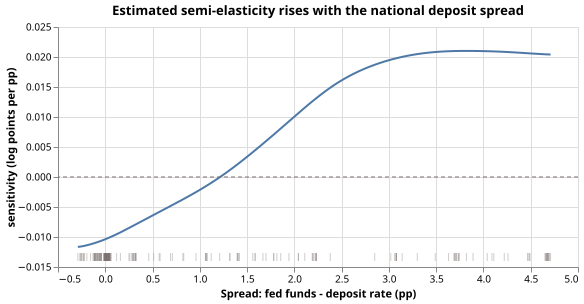

In [17]:
modern_curve = np.linspace(spread.min(), spread.max(), 120)
modern_frame_curve = pl.DataFrame({
    "s": modern_curve, "theta": theta_modern(model_modern, modern_curve)})

alt.Chart(modern_frame_curve).mark_line(color="#4e79a7", strokeWidth=2).encode(
    x=alt.X("s:Q", title="Spread: fed funds - deposit rate (pp)"),
    y=alt.Y("theta:Q", title="sensitivity (log points per pp)"),
).properties(
    width=520, height=240,
    title="Estimated semi-elasticity rises with the national deposit spread"
) + alt.Chart(
    pl.DataFrame({"s": spread})
).mark_tick(color="#79706e", opacity=0.35, size=8, yOffset=110).encode(
    x="s:Q"
) + alt.Chart(pl.DataFrame({"theta": [0.0]})).mark_rule(
    color="#79706e", strokeDash=[4, 3]
).encode(y="theta:Q")

The fitted sensitivity is {eval}`theta_s0` when the offered deposit
rate matches the federal funds rate and {eval}`theta_s45` when it lags
by four and a half percentage points. The marginal-cost identity
requires a positive own-rate response, so it cannot be applied at the
narrow end where the fitted aggregate sensitivity is negative. At the
wide end, the conditional repricing term is {eval}`mc_s45` percentage
points.

A funding rule built from this curve would move from no valid positive
cost translation at a narrow spread to a large one at a wide spread.
That variation is useful only if the curve represents depositor response
rather than the monetary-policy episode. The remaining checks test that
interpretation.


A twelve-month moving-block bootstrap measures residual variation with
the selected model and number of steps held fixed. Subperiod fits test
whether the spread range appears within more than one policy regime. A
final comparison removes the Federal Reserve balance-sheet terms, the
control most capable of reallocating the low-frequency shape.


In [18]:
fitted_mod = model_modern.fitted()
residual_mod = modern["y"].to_numpy() - fitted_mod
ends = np.array([0.5, 4.5])
curvature_mod = float(np.diff(theta_modern(model_modern, ends))[0])

rng = np.random.default_rng(20260817)
draws = np.empty(300)
for b in range(300):
    resampled = modern.with_columns(
        pl.Series("y", fitted_mod + moving_blocks(rng, residual_mod, 12)))
    values = theta_modern(fit_modern(resampled, modern_mstop), ends)
    draws[b] = values[1] - values[0]
lo, hi = np.quantile(draws, [0.10, 0.90])

curvature_mod_fmt = f"{curvature_mod:+.4f}"
mod_lo, mod_hi = f"{lo:+.4f}", f"{hi:+.4f}"
mod_p = f"{(draws > 0).mean():.0%}"
print(f"theta(4.5) - theta(0.5) = {curvature_mod_fmt}")
print(f"block bootstrap (blocks of 12 months): 80% interval "
      f"[{mod_lo}, {mod_hi}], share above zero {mod_p}")

theta(4.5) - theta(0.5) = +0.0270
block bootstrap (blocks of 12 months): 80% interval [+0.0039, +0.0334], share above zero 97%


In [19]:
windows = {
    "before COVID (to 2020-02)": dates <= "2020-02-01",
    "after COVID (from 2021-01)": dates >= "2021-01-01",
}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for label, mask in windows.items():
        subset = modern.filter(pl.Series(mask))
        curve = rolling_cv(subset, modern_grid, folds=10, horizon=6,
                           fitter=fit_modern)
        best = int(modern_grid[int(np.argmin(curve))])
        model = fit_modern(subset, best)
        subset_spread = subset["s"].to_numpy()
        usable = np.array([p for p in (0.5, 2.0, 4.5) if p <= subset_spread.max()])
        values = theta_modern(model, usable)
        rows.append({
            "window": label, "n": subset.height,
            "max spread": round(float(subset_spread.max()), 2),
            "mstop": best,
            "sensitivity": ", ".join(f"{p:.1f}: {v:+.4f}"
                                     for p, v in zip(usable, values)),
            "_theta": values,
        })
display(pl.DataFrame(rows).drop("_theta"))
# Reuse the declared folds so comparisons differ by model, not by split.
pre_max_spread = f"{rows[0]['max spread']:.1f}"
post_n = rows[1]["n"]
post_theta = f"{rows[1]['_theta'][-1]:+.4f}"


window,n,max spread,mstop,sensitivity
str,i64,f64,i64,str
"""before COVID (to 2020-02)""",130,2.23,1,"""0.5: -0.0000, 2.0: -0.0000"""
"""after COVID (from 2021-01)""",65,4.71,59,"""0.5: +0.0138, 2.0: +0.0138, 4.…"


In [20]:
# The rise is a statement about deposits at a given size of the balance sheet.
# This is the same fit with that control removed.
NO_BALANCE_SHEET = (
    "y ~ bols(s_c, intercept=False) + bbs(s_c, center=True, df=1)"
    " + bols(t_c, intercept=False) + bols(covid, intercept=False)"
    " + bols(svb, intercept=False)"
)


def fit_no_balance_sheet(frame, mstop):
    return mb.gamboost(NO_BALANCE_SHEET, data=frame, family=mb.Gaussian(),
                       control=mb.boost_control(mstop=mstop, nu=NU))


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    curve_no_bs = rolling_cv(modern, modern_grid, folds=10, horizon=6,
                             fitter=fit_no_balance_sheet)
best_no_bs = int(modern_grid[int(np.argmin(curve_no_bs))])
ends_no_bs = theta_modern(fit_no_balance_sheet(modern, best_no_bs),
                          np.array([0.5, 4.5]))
print(f"without the balance-sheet control: mstop {best_no_bs}, "
      f"RMSE {curve_no_bs.min():.4f}, sensitivity at 0.5 / 4.5 = "
      f"{ends_no_bs[0]:+.4f} / {ends_no_bs[1]:+.4f}")

rmse_modern = f"{modern_cv.min():.4f}"
rmse_no_bs = f"{curve_no_bs.min():.4f}"
no_bs_low, no_bs_high = f"{ends_no_bs[0]:+.4f}", f"{ends_no_bs[1]:+.4f}"
no_bs_rise = f"{ends_no_bs[1] - ends_no_bs[0]:+.4f}"

without the balance-sheet control: mstop 1920, RMSE 0.0658, sensitivity at 0.5 / 4.5 = +0.0242 / -0.0290


From a spread of one half to four and a half percentage points, the
fitted sensitivity rises by {eval}`curvature_mod_fmt`. The central
eighty percent of the fixed-model bootstrap estimates runs from
{eval}`mod_lo` to {eval}`mod_hi`, and {eval}`mod_p` are positive. The
rise is therefore larger than the residual variation generated within
this specification.

The time-series support is much weaker. Before COVID the spread reaches
only {eval}`pre_max_spread` percentage points, and validation stops at
the first boosting step. The post-2020 window contains {eval}`post_n`
months and estimates {eval}`post_theta` at its widest evaluated spread,
but it does not contain a second independent tightening cycle. The
full-sample curve is learned from the contrast between the low-rate era
and the later tightening.

Removing Federal Reserve assets reverses the fitted shape: sensitivity
moves from {eval}`no_bs_low` to {eval}`no_bs_high`, a change of
{eval}`no_bs_rise`. Six-month forecast error rises from
{eval}`rmse_modern` to {eval}`rmse_no_bs`, so the balance-sheet terms
improve prediction. Better prediction does not identify the spread
effect when both variables move with the same policy regime. The modern
data support a rising conditional association only after that control
is imposed; they do not supply a stable own-rate response for pricing.


## Conclusions

When a
higher rate reprices the entire book, marginal deposit cost equals the
posted rate plus the reciprocal of the own-rate sensitivity. This is
why a low posted rate can coexist with a high marginal cost.

Neither aggregate sample identifies the sensitivity needed by that
formula. The historical sample provides broad rate coverage but measures
M1 against a market rate; its declining sensitivity disappears when the
time trend can curve. The modern sample measures deposits and an offered
rate, but its rising sensitivity is learned from one policy transition
and reverses when the balance-sheet adjustment is removed.

Substituting the fitted aggregate slopes into the cost formula shows how
strongly the result depends on interpreting those slopes as a bank's own-rate
response. Their instability rules out that
substitution for the public series used here.

A pricing estimate needs balances and offered rates at the bank or
account level, together with variation that separates a bank's rate
choice from local deposit demand, its funding need, and monetary policy.
Local deposit-market concentration is one source of such variation in
the banking literature {cite:p}`drechsler2017deposits`. Those data and an identification design are needed to estimate marginal
deposit cost for a bank's funding decision.


```{bibliography}
:filter: docname in docnames
```
